In [9]:
# Credit Risk Assessment and Decision Support System

## Dataset: Freddie Mac Mortgage Dataset

## Objective: Build an explainable credit risk assessment system capable of:
## - Predicting probability of default (PD)
## - Creating scorecards
## - Performing scenario analysis
## - Providing GenAI-powered risk explanations

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries Loaded Successfully")

Matplotlib is building the font cache; this may take a moment.


Libraries Loaded Successfully


In [3]:
df = pd.read_csv("../data/raw/FreddieMac.csv")

print("Shape:", df.shape)

df.head()

Shape: (291451, 28)


/var/folders/92/ptnjnlq917lb_tj60r_31src0000gn/T/ipykernel_45206/3397016626.py:1: DtypeWarning: Columns (0: PostalCode) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/FreddieMac.csv")


,CreditScore,FirstPaymentDate,FirstTimeHomebuyer,MaturityDate,MSA,MIP,Units,Occupancy,OCLTV,DTI,OrigUPB,LTV,OrigInterestRate,Channel,PPM,ProductType,PropertyState,PropertyType,PostalCode,LoanSeqNum,LoanPurpose,OrigLoanTerm,NumBorrowers,SellerName,ServicerName,EverDelinquent,MonthsDelinquent,MonthsInRepayment
0,0,199902,N,202901,16974,25,1,O,89,27,117000,89,6.750,T,N,FRM,IL,SF,60400,F199Q1268030,P,360,2,FL,WASHINGTONMUTUALBANK,0,0,52
1,0,199902,N,202901,19740,0,1,O,73,17,109000,73,6.500,R,N,FRM,CO,SF,80200,F199Q1015092,N,360,1,FT,CHASEHOMEFINANCELLC,0,0,144
2,0,199902,N,202901,29940,0,1,O,75,16,88000,75,6.875,T,N,FRM,KS,SF,66000,F199Q1266886,N,360,2,FL,WASHINGTONMUTUALBANK,0,0,67
3,0,199902,N,202901,31084,0,1,O,76,14,160000,76,6.875,R,N,FRM,CA,SF,90700,F199Q1178167,N,360,2,GM,GMACMTGECORP,0,0,35
4,0,199902,N,202901,35644,0,1,O,78,18,109000,78,7.125,R,N,FRM,NJ,SF,7600,F199Q1178517,N,360,2,GM,GMACMTGECORP,0,0,54


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 291451 entries, 0 to 291450
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   CreditScore         291451 non-null  int64  
 1   FirstPaymentDate    291451 non-null  int64  
 2   FirstTimeHomebuyer  291451 non-null  str    
 3   MaturityDate        291451 non-null  int64  
 4   MSA                 291451 non-null  str    
 5   MIP                 291451 non-null  int64  
 6   Units               291451 non-null  int64  
 7   Occupancy           291451 non-null  str    
 8   OCLTV               291451 non-null  int64  
 9   DTI                 291451 non-null  int64  
 10  OrigUPB             291451 non-null  int64  
 11  LTV                 291451 non-null  int64  
 12  OrigInterestRate    291451 non-null  float64
 13  Channel             291451 non-null  str    
 14  PPM                 291451 non-null  str    
 15  ProductType         291451 non-null  str    


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percent": round(
        (df.isnull().sum() / len(df)) * 100,
        2
    )
})
missing.sort_values(
    by="Missing_Percent",
    ascending=False
).head(20)

,Missing_Count,Missing_Percent
SellerName,24994,8.58
CreditScore,0,0.00
FirstPaymentDate,0,0.00
MonthsDelinquent,0,0.00
EverDelinquent,0,0.00
ServicerName,0,0.00
NumBorrowers,0,0.00
OrigLoanTerm,0,0.00
LoanPurpose,0,0.00
LoanSeqNum,0,0.00


In [11]:
# Handle missing SellerName

df["SellerName"] = df["SellerName"].fillna("Unknown")

print(
    df["SellerName"].isnull().sum()
)

0


In [12]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [13]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:\n")

for col in df.columns:
    print(col)

Rows: 291451
Columns: 28

Column Names:

CreditScore
FirstPaymentDate
FirstTimeHomebuyer
MaturityDate
MSA
MIP
Units
Occupancy
OCLTV
DTI
OrigUPB
LTV
OrigInterestRate
Channel
PPM
ProductType
PropertyState
PropertyType
PostalCode
LoanSeqNum
LoanPurpose
OrigLoanTerm
NumBorrowers
SellerName
ServicerName
EverDelinquent
MonthsDelinquent
MonthsInRepayment


In [14]:
# Target distribution

target_dist = df["EverDelinquent"].value_counts()

print(target_dist)

print("\nPercentage:")

print(
    round(
        df["EverDelinquent"].value_counts(normalize=True)*100,
        2
    )
)

EverDelinquent
0    233788
1     57663
Name: count, dtype: int64

Percentage:
EverDelinquent
0    80.22
1    19.78
Name: proportion, dtype: float64


In [15]:
# Numerical summary

df.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,291451.0,708.936991,68.408791,0.0,675.00,717.000,753.000,849.00
FirstPaymentDate,291451.0,199904.760553,13.821228,199901.0,199903.00,199904.000,199905.000,201303.00
MaturityDate,291451.0,202902.367043,16.090508,202402.0,202902.00,202903.000,202904.000,204302.00
MIP,291451.0,9.216685,12.648273,0.0,0.00,0.000,25.000,55.00
Units,291451.0,1.026022,0.202986,0.0,1.00,1.000,1.000,4.00
OCLTV,291451.0,76.960529,15.236154,0.0,70.00,80.000,90.000,110.00
DTI,291451.0,30.033453,13.203974,0.0,22.00,31.000,39.000,65.00
OrigUPB,291451.0,124940.387921,53657.440624,8000.0,83000.00,117000.000,160000.000,497000.00
LTV,291451.0,76.937986,15.225298,0.0,70.00,80.000,90.000,103.00
OrigInterestRate,291451.0,6.926547,0.343541,4.0,6.75,6.875,7.125,12.35


In [16]:
#CreditScore contains 0 values that may represent missing credit information. Needs further investigation during preprocessing.

In [18]:
(df["CreditScore"] == 0).sum()

np.int64(1189)

In [19]:
round((df["CreditScore"] == 0).mean()*100,2)

np.float64(0.41)

In [22]:
median_score = df["CreditScore"].median()

df["CreditScore"] = df["CreditScore"].replace(0, np.nan)
df["CreditScore"] = df["CreditScore"].fillna(median_score)

In [23]:
(df["CreditScore"] == 0).sum()

np.int64(0)

In [17]:
df.groupby("EverDelinquent")[
    ["CreditScore",
     "DTI",
     "LTV",
     "OrigInterestRate",
     "OrigUPB"]
].mean()

,CreditScore,DTI,LTV,OrigInterestRate,OrigUPB
EverDelinquent,,,,,
0,715.976560,29.626170,76.440934,6.916239,126741.941417
1,680.395869,31.684737,78.953228,6.968340,117636.196521


In [24]:
df.groupby("EverDelinquent")["MonthsDelinquent"].describe()

,count,mean,std,min,25%,50%,75%,max
EverDelinquent,,,,,,,,
0,233788.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,57663.0,9.288591,17.973419,1.0,1.0,2.0,9.0,180.0


In [25]:
df.groupby("EverDelinquent")["CreditScore"].describe()

,count,mean,std,min,25%,50%,75%,max
EverDelinquent,,,,,,,,
0,233788.0,718.626345,48.481490,335.0,686.0,725.0,757.0,849.0
1,57663.0,684.437022,52.733192,342.0,646.0,683.0,723.0,838.0


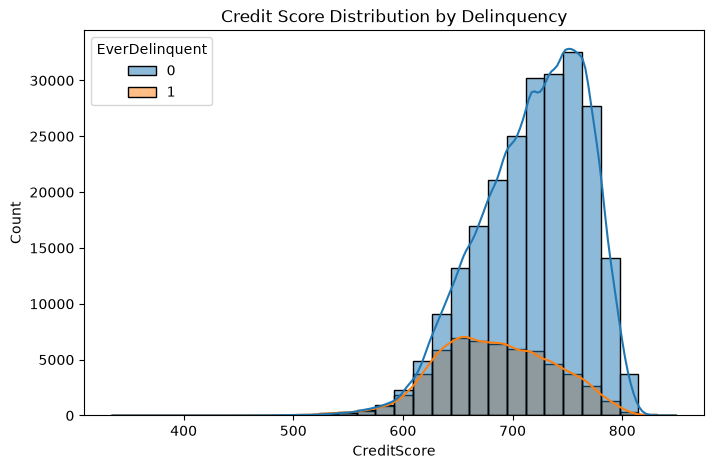

In [26]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="CreditScore",
    hue="EverDelinquent",
    bins=30,
    kde=True
)

plt.title("Credit Score Distribution by Delinquency")
plt.show()

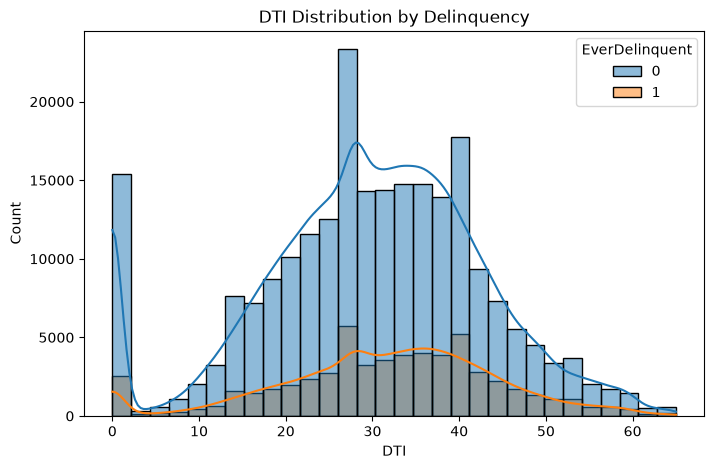

In [27]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="DTI",
    hue="EverDelinquent",
    bins=30,
    kde=True
)

plt.title("DTI Distribution by Delinquency")
plt.show()

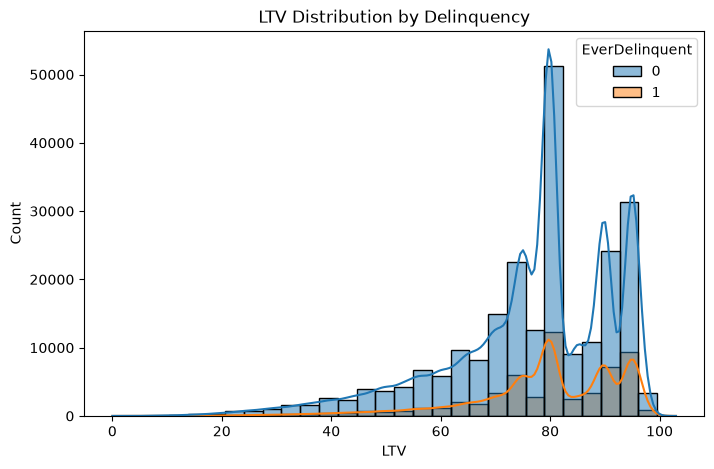

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="LTV",
    hue="EverDelinquent",
    bins=30,
    kde=True
)

plt.title("LTV Distribution by Delinquency")
plt.show()

In [29]:
df["DTI"].nunique()

66

In [30]:
df["LTV"].nunique()

97

In [31]:
df["LTV"].value_counts().head(20)

LTV
80    54503
95    37209
90    29343
75    17918
79     7329
85     6728
78     5981
70     5654
74     5537
77     5274
73     4975
72     4619
89     4522
97     4235
76     4131
69     4013
71     3954
88     3934
65     3830
67     3467
Name: count, dtype: int64

In [32]:
(df["DTI"] == 0).sum()

np.int64(17796)

In [33]:
round((df["DTI"] == 0).mean()*100,2)

np.float64(6.11)

In [34]:
df.groupby(df["DTI"] == 0)["EverDelinquent"].mean()

DTI
False    0.201458
True     0.142335
Name: EverDelinquent, dtype: float64

In [35]:
df[df["DTI"] == 0][
    ["CreditScore","LTV","OrigUPB","OrigInterestRate"]
].describe()

,CreditScore,LTV,OrigUPB,OrigInterestRate
count,17796.000000,17796.000000,17796.000000,17796.000000
mean,722.760171,74.495336,130855.922679,6.766315
std,53.106606,14.823594,58489.551417,0.371132
min,466.000000,0.000000,15000.000000,4.750000
25%,691.000000,68.000000,86000.000000,6.625000
50%,732.000000,78.000000,120000.000000,6.750000
75%,764.000000,80.000000,167000.000000,6.875000
max,840.000000,100.000000,410000.000000,12.350000


In [36]:
df[df["DTI"] > 0][
    ["CreditScore","LTV","OrigUPB","OrigInterestRate"]
].describe()

,CreditScore,LTV,OrigUPB,OrigInterestRate
count,273655.000000,273655.000000,273655.000000,273655.000000
mean,711.153343,77.096834,124555.696041,6.936967
std,50.989482,15.237528,53305.431556,0.339058
min,335.000000,0.000000,8000.000000,4.000000
25%,675.000000,71.000000,83000.000000,6.750000
50%,717.000000,80.000000,117000.000000,6.875000
75%,752.000000,90.000000,160000.000000,7.125000
max,849.000000,103.000000,497000.000000,11.500000


| Metric           | DTI = 0   | DTI > 0   |
| ---------------- | --------- | --------- |
| Credit Score     | **722.8** | **711.2** |
| LTV              | **74.5**  | **77.1**  |
| Interest Rate    | **6.77**  | **6.94**  |
| Delinquency Rate | **14.2%** | **20.1%** |


#### DTI contains 17,796 observations (6.11%) with a value of 0. These borrowers exhibit higher average credit scores, lower LTV, lower interest rates, and lower delinquency rates compared with borrowers having DTI > 0. Therefore, DTI=0 is retained for further analysis and is not currently treated as a missing value.

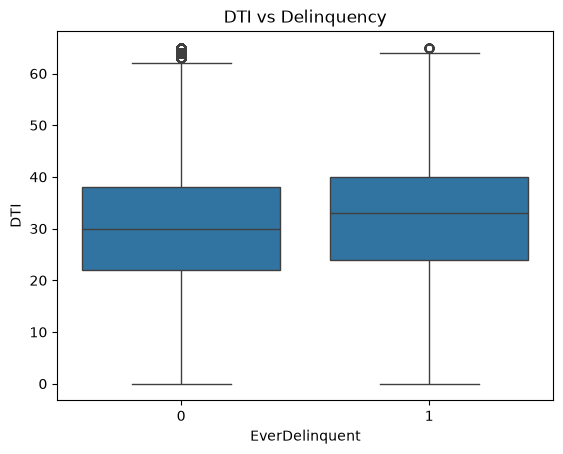

In [37]:
sns.boxplot(
    data=df,
    x="EverDelinquent",
    y="DTI"
)

plt.title("DTI vs Delinquency")
plt.show()

In [38]:
df["DTI_Bucket"] = pd.cut(
    df["DTI"],
    bins=[0,20,30,40,50,70]
)

df.groupby("DTI_Bucket")["EverDelinquent"].mean()

DTI_Bucket
(0, 20]     0.171874
(20, 30]    0.183291
(30, 40]    0.212153
(40, 50]    0.232804
(50, 70]    0.230081
Name: EverDelinquent, dtype: float64

<Axes: xlabel='EverDelinquent', ylabel='CreditScore'>

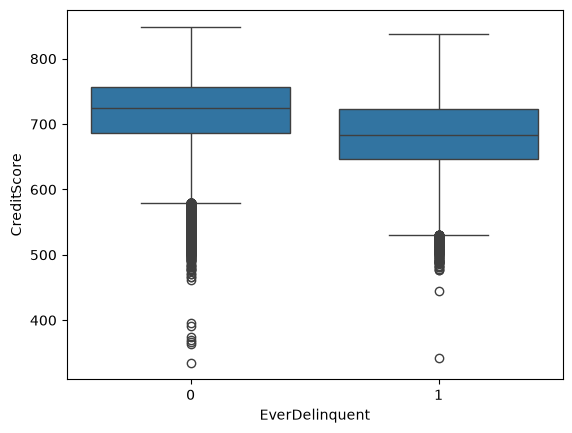

In [39]:
sns.boxplot(
    x="EverDelinquent",
    y="CreditScore",
    data=df
)